## MTL Trajet: 01 Purpose Destination Land Use (Flag 1)

### Dataset Overview
MTL Trajet 2016 mobility data with trip purpose, mode, timing, endpoints, trip metrics, and Montréal PUM 2050 destination land-use categories. User IDs distinguish participants, and the point tables provide speed profiles. The single-user case includes a repeated work corridor.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze how trip purpose relates to official destination land-use, departure time, distance, and transport mode across the supplied multiple-user trajectories.

Role: Urban mobility and land-use analyst


Category: Trip purpose, destination land-use, timing, distance, and mode

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display
points=pd.read_csv('trajectory_points.csv')


## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Which destination land-use types are represented across trip purposes, and how are health- and work-purpose trips distributed?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

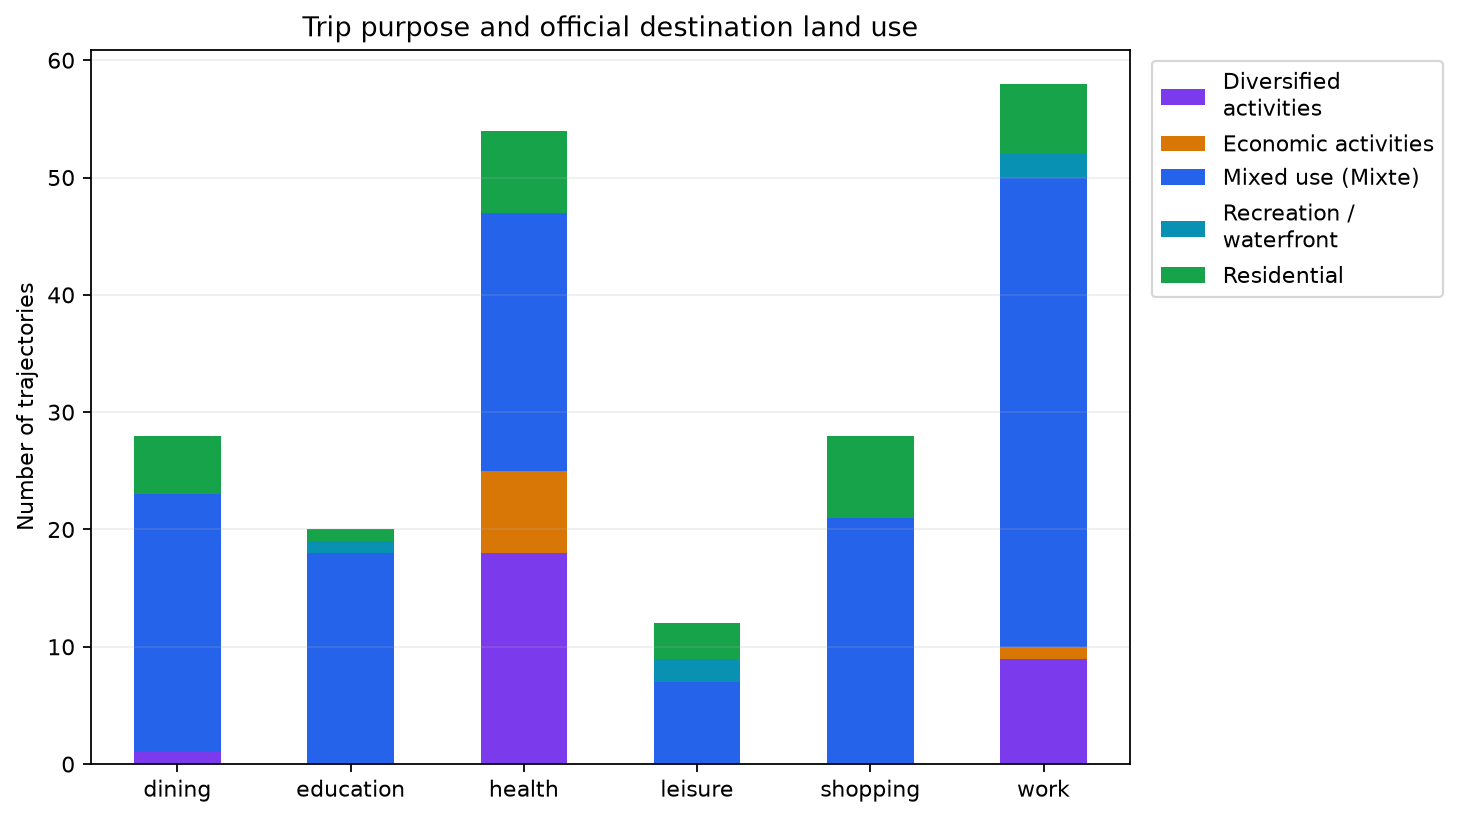

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
df = pd.read_csv(dataset_path)
points = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))
print(pd.crosstab(df.purpose_group, df.destination_land_use))

from IPython.display import Image, display
display(Image(filename='visualizations/purpose_by_destination_land_use.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "purpose_conditioned_destination_land_use",
  "insight": "Mixte destinations occur in every trip-purpose group. Health and work trips both include substantial Mixte components, with diversified-activity destinations also represented in both groups.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Purpose by Destination Land-use",
    "description": "Recomputed from the delivered fixed GPS coordinates and the archived official PUM2050 Affectatio polygons; Unmapped denotes no containing polygon.",
    "file": "visualizations/purpose_by_destination_land_use.png"
  },
  "question": "Which destination land-use types are represented across trip purposes, and how are health- and work-purpose trips distributed?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\ndf = pd.read_csv(dataset_path)\npoints = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))\nprint(pd.crosstab(df.purpose_group, df.destination_land_use))\n",
  "insight_type": "factor_relationship",
  "insight_value": {
    "Activités diversifiées": {
      "dining": 1,
      "education": 0,
      "health": 18,
      "leisure": 0,
      "shopping": 0,
      "work": 9
    },
    "Activités économiques": {
      "dining": 0,
      "education": 0,
      "health": 7,
      "leisure": 0,
      "shopping": 0,
      "work": 1
    },
    "Mixte": {
      "dining": 22,
      "education": 18,
      "health": 22,
      "leisure": 7,
      "shopping": 21,
      "work": 40
    },
    "Récréation et accès aux rives": {
      "dining": 0,
      "education": 1,
      "health": 0,
      "leisure": 2,
      "shopping": 0,
      "work": 2
    },
    "Résidentiel": {
      "dining": 5,
      "education": 1,
      "health": 7,
      "leisure": 3,
      "shopping": 7,
      "work": 6
    }
  },
  "evidence": "Official endpoint join: health has 22 Mixte and 18 diversified-activity destinations; work has 40 and 9, respectively.",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "gps_position",
    "land_use_reference",
    "trajectory_id"
  ]
}

### **Question 2**: Which purposes have concentrated departure periods, and which are distributed across more times of day?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

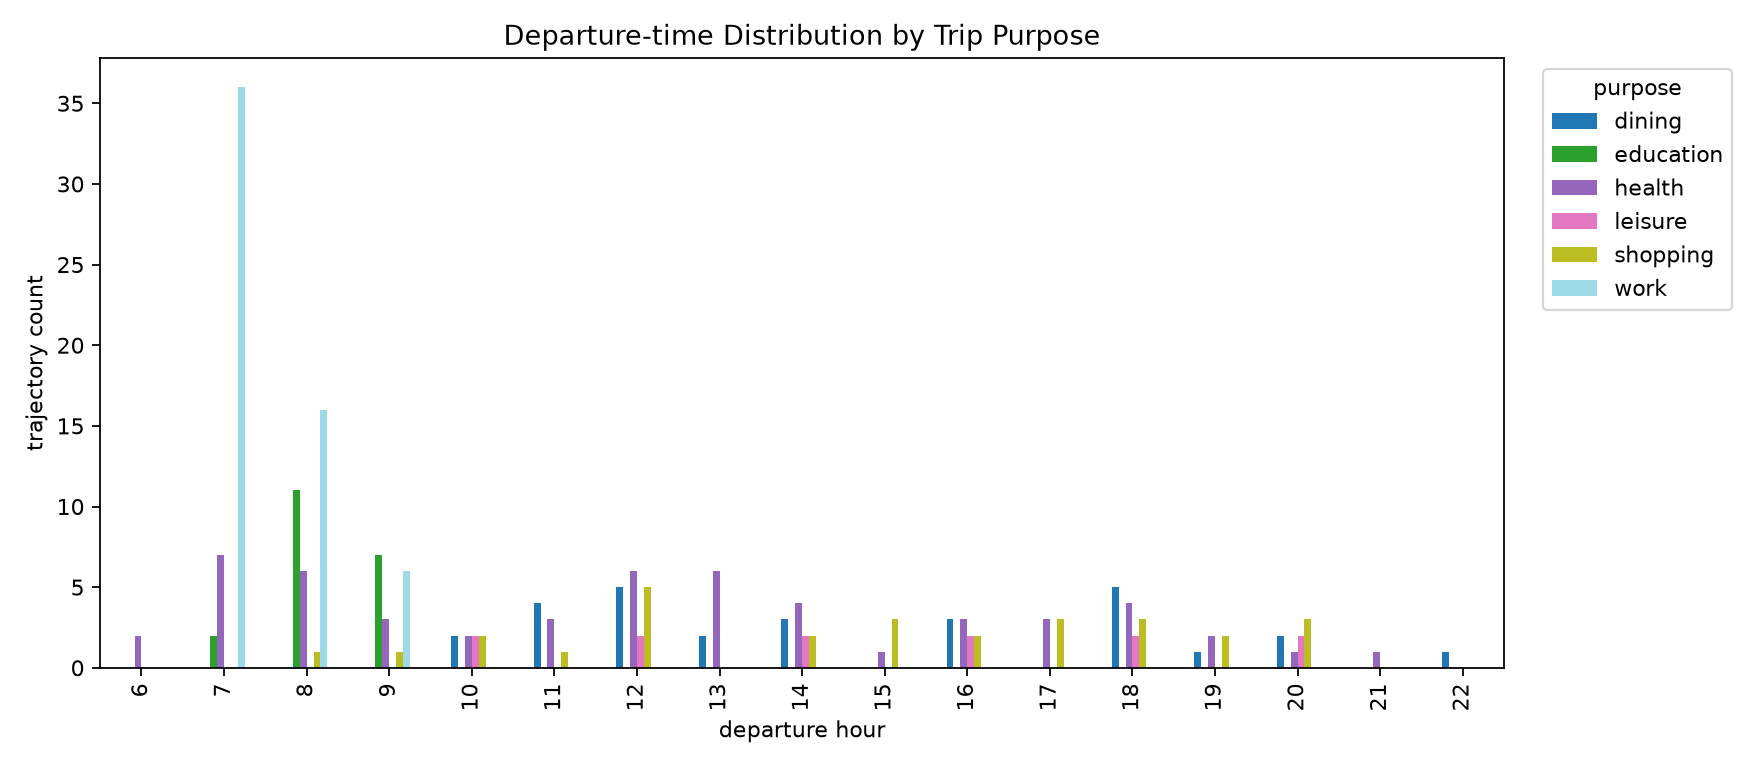

In [ ]:
df.groupby('purpose_group').start_hour.agg(['count','min','median','max','nunique'])
from IPython.display import Image, display
display(Image(filename='visualizations/departure_time_by_purpose.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "purpose_conditioned_departure_time",
  "insight": "Work- and education-related trajectories have clearly concentrated departure periods, whereas shopping, dining, and leisure trajectories are distributed across a broader set of departure times.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Purpose-conditioned Departure Time",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/departure_time_by_purpose.png"
  },
  "question": "Which purposes have concentrated departure periods, and which are distributed across more times of day?",
  "code": "df.groupby('purpose_group').start_hour.agg(['count','min','median','max','nunique'])",
  "insight_type": "group_comparison",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 3**: How do distance distributions and transport-mode compositions differ among shopping, dining, health, and work trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

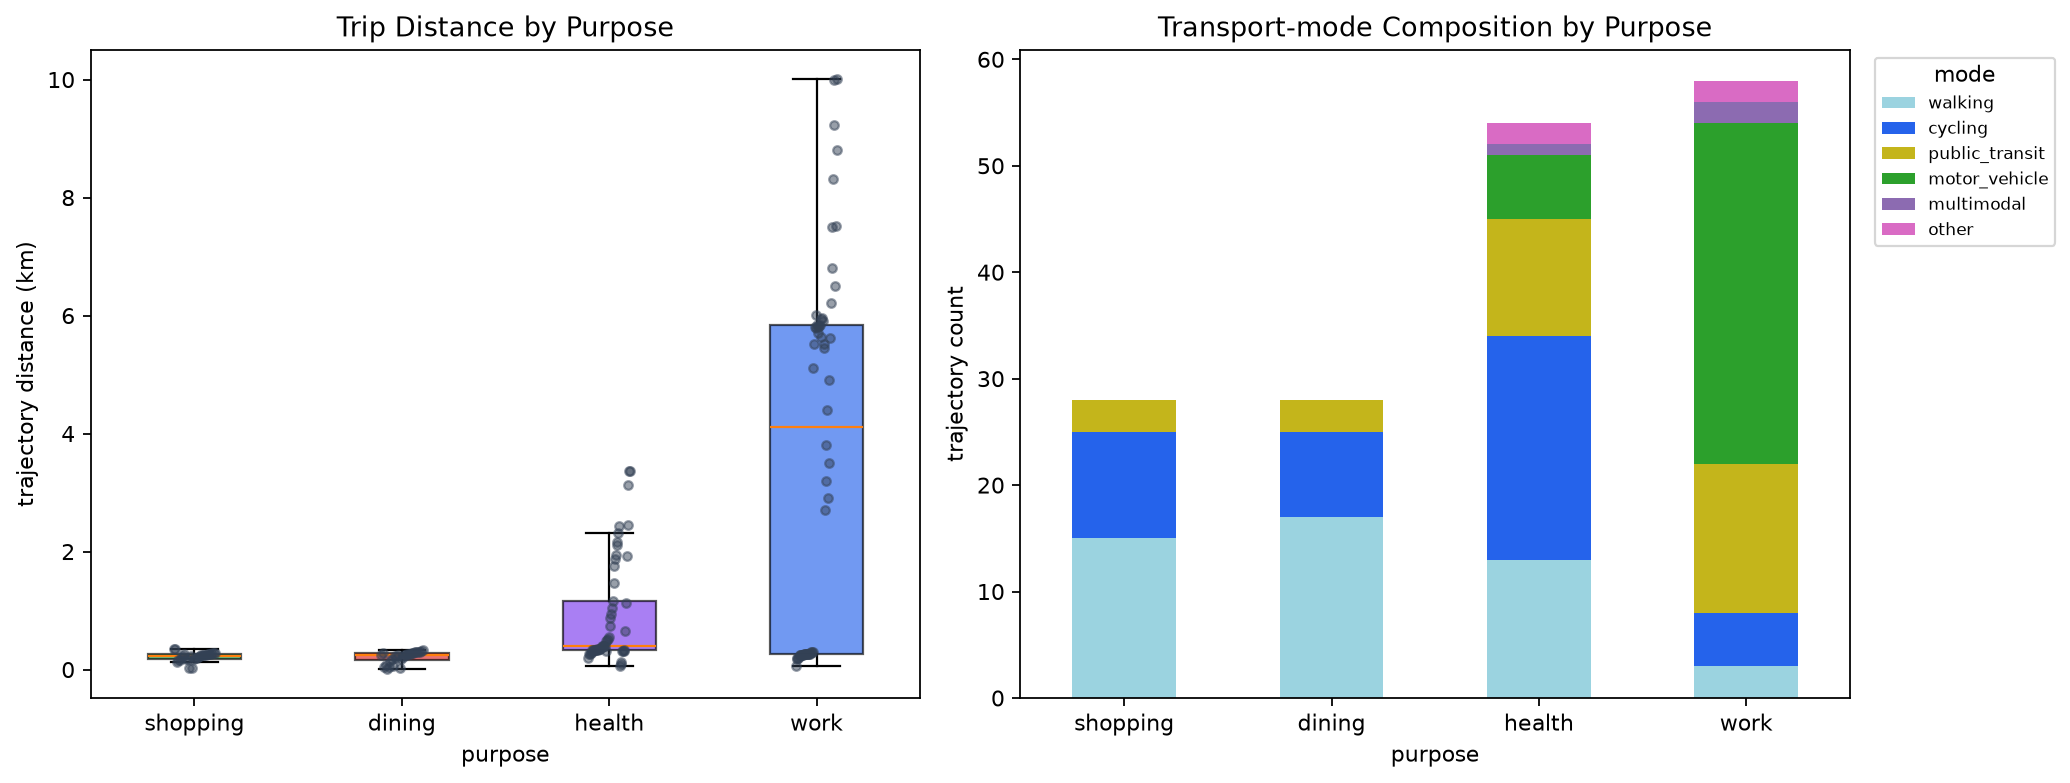

In [ ]:
pd.crosstab(df.purpose_group, df.mode_group).reindex(['shopping','dining','health','work'])
from IPython.display import Image, display
display(Image(filename='visualizations/purpose_distance_mode_profile.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "purpose_distance_and_mode_structure",
  "insight_type": "factor_relationship",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Purpose-specific Distance and Transport Mode Structure",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/purpose_distance_mode_profile.png"
  },
  "question": "How do distance distributions and transport-mode compositions differ among shopping, dining, health, and work trips?",
  "code": "pd.crosstab(df.purpose_group, df.mode_group).reindex(['shopping','dining','health','work'])",
  "insight": "Shopping and dining trips are generally shorter and less motor-vehicle-oriented than work trips.",
  "evidence": "Shopping and dining trajectories are generally short, whereas health trips are longer and span a broader distance range; work trips have the widest distance distribution and are generally the longest. Walking, cycling, and public transit together account for most modes in the first three purposes; work trips use all mode categories, with motor vehicles the largest single group.",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "gps_position",
    "transport_mode",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 1)

Mixte destinations occur in every trip-purpose group. Health and work trips both include substantial Mixte components, with diversified-activity destinations also represented in both groups. Work- and education-related trajectories have clearly concentrated departure periods, whereas shopping, dining, and leisure trajectories are distributed across a broader set of departure times. Shopping and dining trips are generally shorter and less motor-vehicle-oriented than work trips.
